In [1]:
import os, glob
import pandas as pd, numpy as np
import xgboost
from xgboost import XGBRegressor

# ---------- 1. 读数据（自动找路径） ----------
def find(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    assert hits, f"{name} not found under /kaggle/input"
    return hits[0]

train = pd.read_csv(find("train.csv"), parse_dates=["date"])
test  = pd.read_csv(find("test.csv"),  parse_dates=["date"])
print(train.shape, test.shape, "xgboost", xgboost.__version__)

# ---------- 2. 特征函数 ----------
def make_feats_base(df):
    df = df.copy()
    d = df["date"]
    df["dayofweek"]  = d.dt.dayofweek
    df["month"]      = d.dt.month
    df["year"]       = d.dt.year
    df["day"]        = d.dt.day
    df["weekofyear"] = d.dt.isocalendar().week.astype(int)
    df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)
    return df

def add_lag(df, history, days=364):
    """单日去年同期（52周对齐星期几）"""
    h = history[["date", "store", "item", "sales"]].copy()
    h["date"] = h["date"] + pd.Timedelta(days=days)
    h = h.rename(columns={"sales": f"lag_{days}"})
    return df.merge(h, on=["date", "store", "item"], how="left")

def add_centered_lag(df, history, days=364, window=28):
    """去年同期的 window 天中心滑动均值"""
    h = (history[["date", "store", "item", "sales"]]
         .sort_values(["store", "item", "date"]).copy())
    h["sales"] = h.groupby(["store", "item"])["sales"].transform(
        lambda s: s.rolling(window, center=True, min_periods=1).mean())
    h["date"] = h["date"] + pd.Timedelta(days=days)
    h = h.rename(columns={"sales": f"lag_{days}_c{window}"})
    return df.merge(h, on=["date", "store", "item"], how="left")

def build(df, history):
    df = make_feats_base(df)
    df = add_lag(df, history, 364)
    df = add_centered_lag(df, history, 364, 28)
    return df

FEATS = ["store", "item", "dayofweek", "month", "year", "day", "weekofyear",
         "is_weekend", "lag_364", "lag_364_c28"]

params = dict(objective="count:poisson", n_estimators=500, learning_rate=0.05,
              max_depth=6, subsample=0.8, colsample_bytree=0.8, random_state=42)

# ---------- 3. 全量训练 ----------
X_all  = build(train, train).dropna(subset=["lag_364", "lag_364_c28"])
X_test = build(test, train)

# 2018Q1 的去年同期（含窗口）都应落在已知历史内
assert X_test["lag_364"].isna().sum() == 0
assert X_test["lag_364_c28"].isna().sum() == 0

print(X_all.shape, X_test.shape)     # 期望 (731000, 12) (45000, 13)
print(FEATS)
print(params)

m = XGBRegressor(**params).fit(X_all[FEATS], X_all["sales"])

# ---------- 4. 预测并生成提交文件 ----------
pred = np.clip(m.predict(X_test[FEATS]), 0, None)
X_test["sales"] = pred

sub = X_test[["id", "sales"]].sort_values("id")
sub.to_csv("/kaggle/working/submission.csv", index=False)

print(sub.shape, sub.sales.min(), sub.sales.isna().sum())
print(sub["sales"].describe())

(913000, 4) (45000, 4) xgboost 3.4.1
(731000, 12) (45000, 12)
['store', 'item', 'dayofweek', 'month', 'year', 'day', 'weekofyear', 'is_weekend', 'lag_364', 'lag_364_c28']
{'objective': 'count:poisson', 'n_estimators': 500, 'learning_rate': 0.05, 'max_depth': 6, 'subsample': 0.8, 'colsample_bytree': 0.8, 'random_state': 42}
(45000, 2) 8.547089576721191 0
count    45000.000000
mean        47.639011
std         23.586142
min          8.547090
25%         28.219853
50%         44.348309
75%         62.981128
max        142.450073
Name: sales, dtype: float64


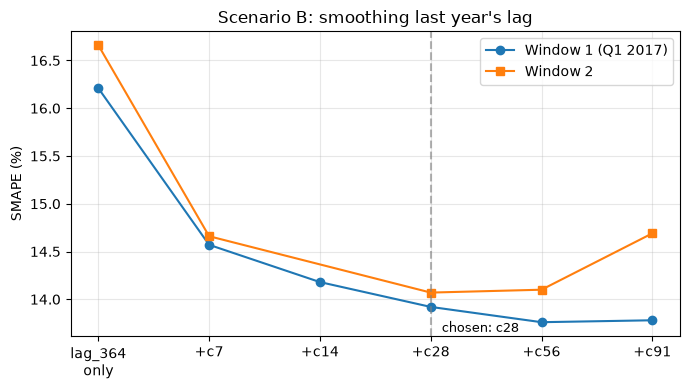

In [1]:
import matplotlib.pyplot as plt

labels = ["lag_364\nonly", "+c7", "+c14", "+c28", "+c56", "+c91"]
w1 = [16.21, 14.57, 14.18, 13.92, 13.76, 13.78]
w2 = [16.66, 14.66, None,  14.07, 14.10, 14.69]   # 窗口2没跑c14

fig, ax = plt.subplots(figsize=(7, 4))
x = range(len(labels))
ax.plot(x, w1, marker="o", label="Window 1 (Q1 2017)")
x2 = [i for i, v in enumerate(w2) if v is not None]
ax.plot(x2, [v for v in w2 if v is not None], marker="s", label="Window 2")
ax.axvline(3, ls="--", color="gray", alpha=0.6)
ax.annotate("chosen: c28", (3, 13.92), textcoords="offset points",
            xytext=(8, -18), fontsize=9)
ax.set_xticks(list(x)); ax.set_xticklabels(labels)
ax.set_ylabel("SMAPE (%)"); ax.set_title("Scenario B: smoothing last year's lag")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../assets/scenario_b_window.png", dpi=150)   # 路径按你notebook的位置调整，保存到 assets/
plt.show()